In [1]:
%pip install -q landingai pillow matplotlib gTTS


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install landingai


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 10.4.0
JPEG encoding successful: 633 bytes


## Meicine Bottles

In [4]:

import os
from getpass import getpass
from landingai.predict import Predictor

API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "85e351ec-877a-4a1d-9d45-d3aa2c3cf93d"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

Enter your LandingAI API Key:  ········


LandingAI predictor initialized successfully.


In [5]:
!pip install pillow numpy ipywidgets


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [6]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_paths = filedialog.askopenfilenames(
    title="Select Medicine Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_paths))

Total images selected: 15



Filename: 8A-DpUCaupKUvBKXnehKynqxnPu_jpg.rf.1e4ab8c755b7bfc3fc24fbf067fec276.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


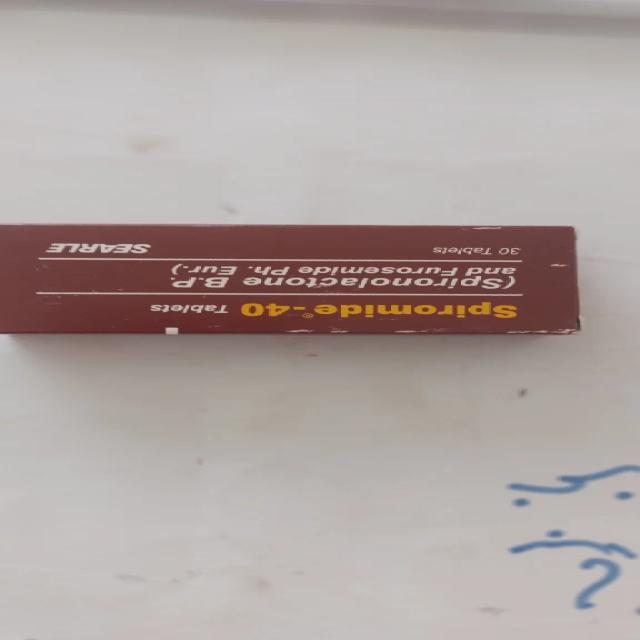


Filename: 8A2llIANwEJLkfmwibyyQGyfMXk_jpg.rf.9482eb26f019f60321947891329cff8a.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


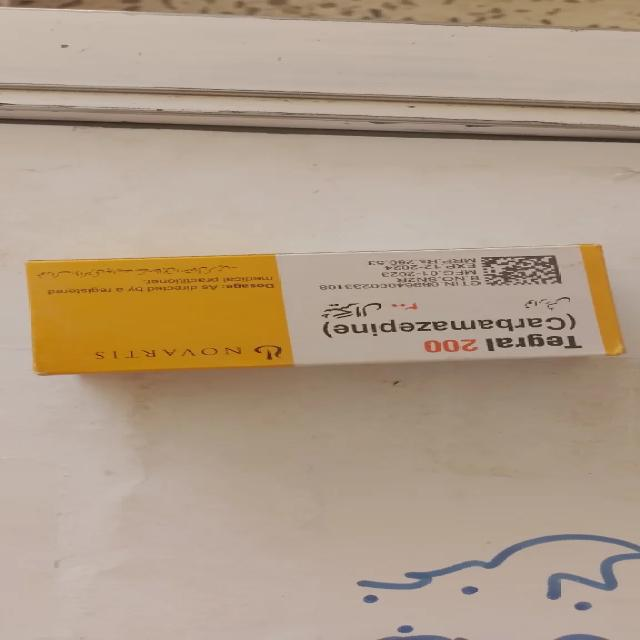


Filename: 8A4LMaoydMoikUOsIIlNyOLFvus_jpg.rf.23e7163f0f811f30298d09e9e95f3f6d.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


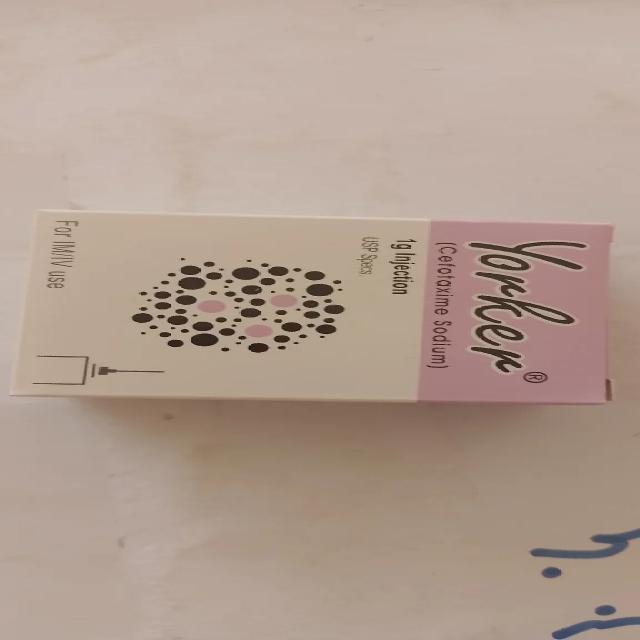


Filename: 8A5fkelQxiJkmqnLcakMhOpPwWo_jpg.rf.c7e66f88257ac5ca141010235455207c.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


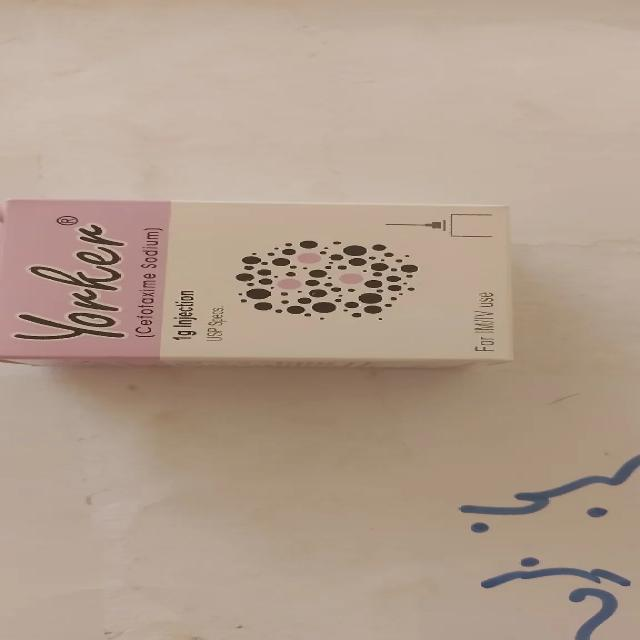


Filename: 8A9yuBWlMqOQoQgGBeYwtSkTHaz_jpg.rf.a095333fa07a91865e293ce9985c4ca2.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


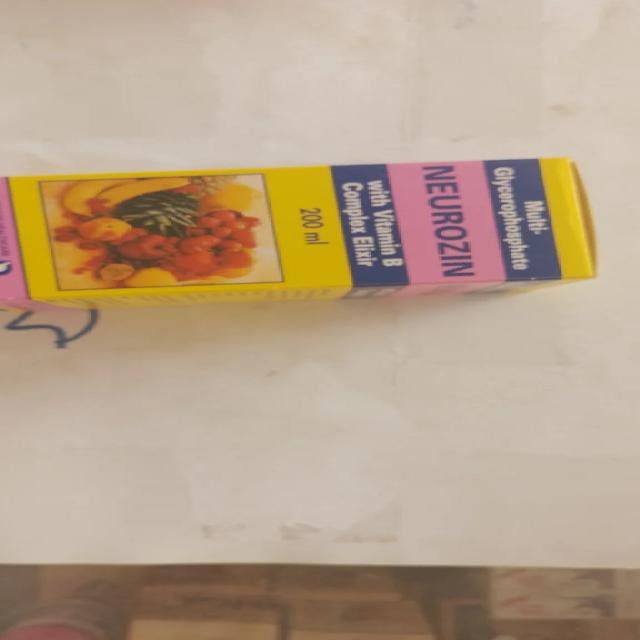


Filename: 8AAoHGPDmQJCyxYgLwvpOGKiAMd_jpg.rf.7230d6935d2bc3489ce05b0958cc520e.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


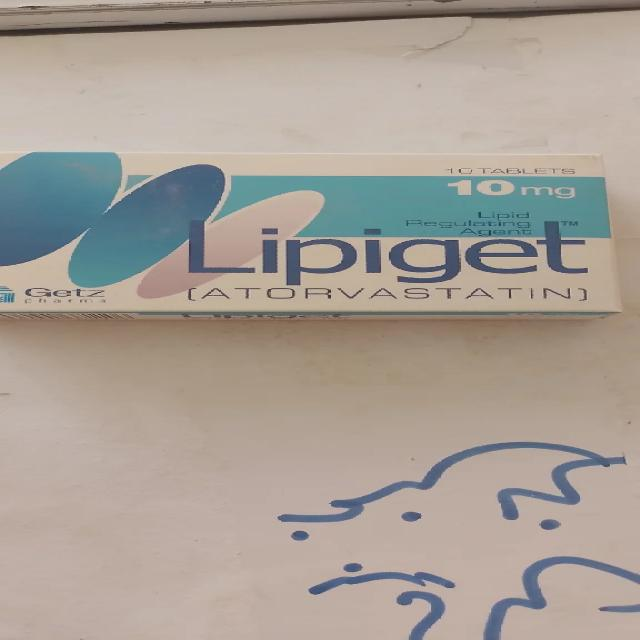


Filename: 8AdVxOOlfNPJrARuofCjCdebGXm_jpg.rf.837d4dacdf539568149632fd04736820.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


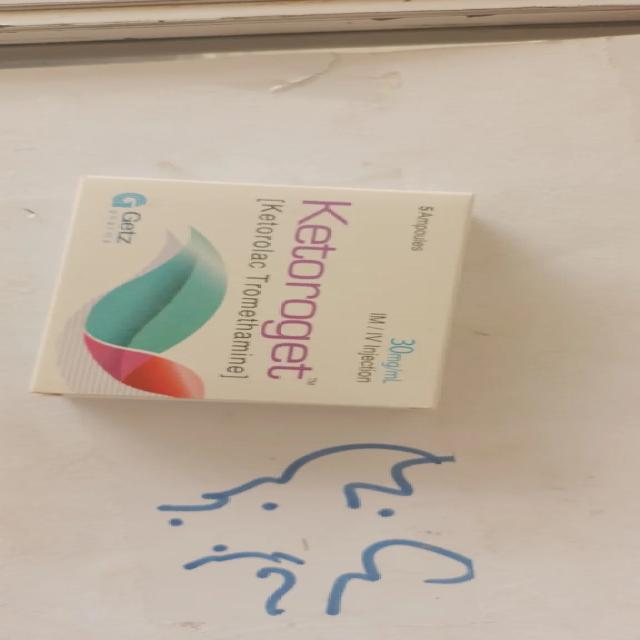


Filename: 8AfrNAzggLvKJPepzWRndHfiYcw_jpg.rf.abdc0b03ee254550da9536979f358b33.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


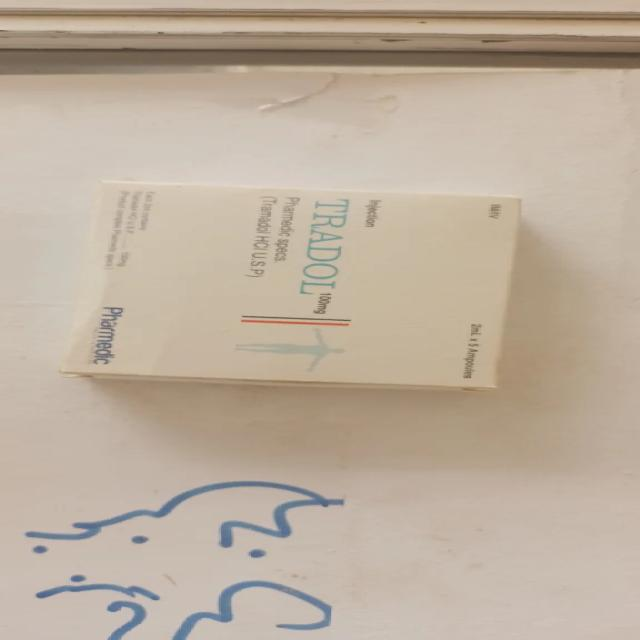


Filename: 8ARGoXzVTYflFhcUYwVjPMRQZXk_jpg.rf.f8d23f16dd05be6898f923adacb52368.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


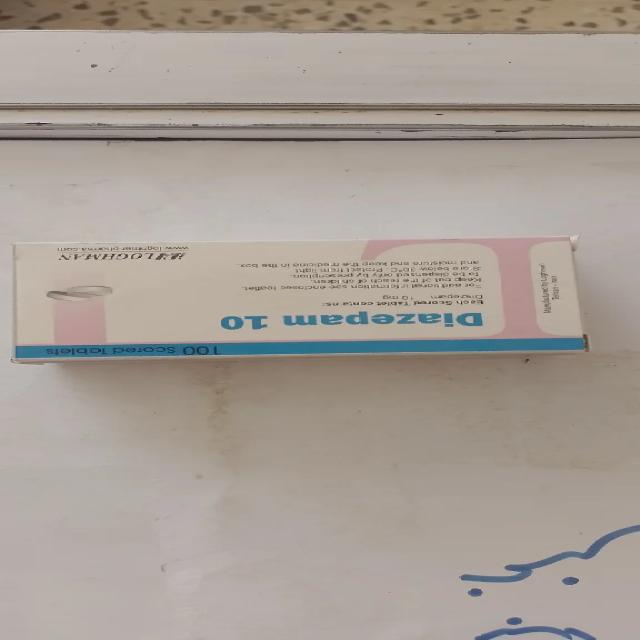


Filename: 8AWwUkCKHmlgHadsssoaunBqXSx_jpg.rf.e8cb1b73c96eb07606e08c9776113e7e.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


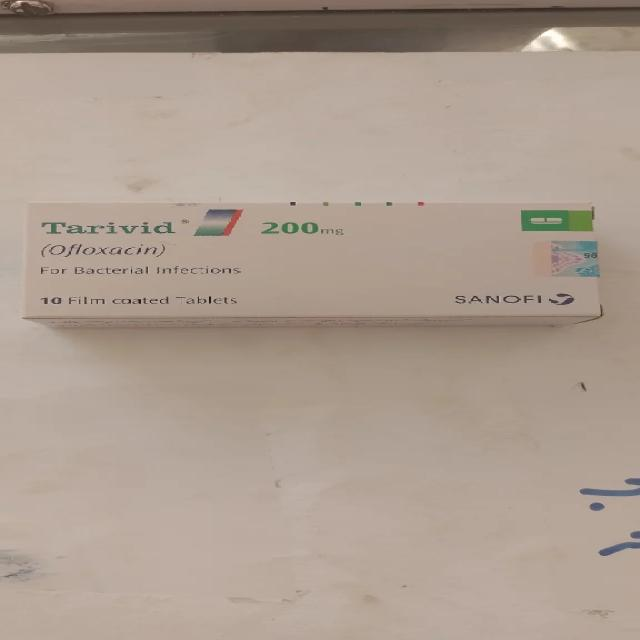


Filename: 8B1AcVVmHdmgiwOhcSUcvagjDDd_jpg.rf.b4f4e6612a8984171dbc65eb13278d18.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


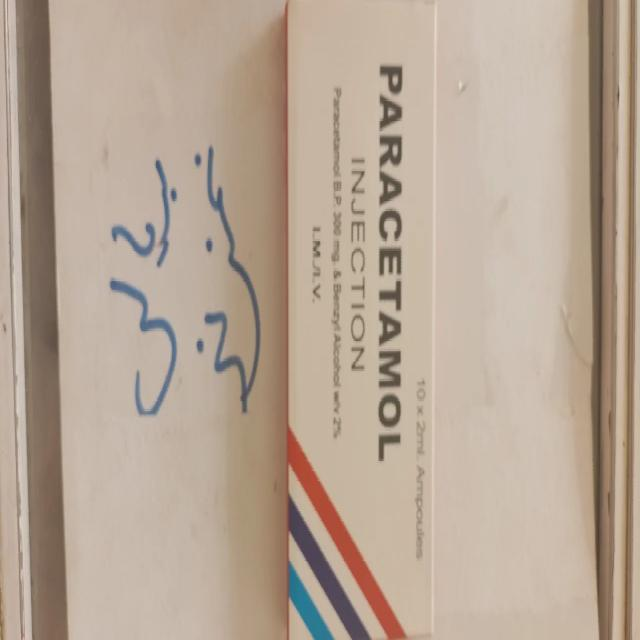


Filename: 8B5UBUvkOfINvFjDkyVrVcqqdOl_jpg.rf.2d875737176bb6f74c35bbe668f01b71.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


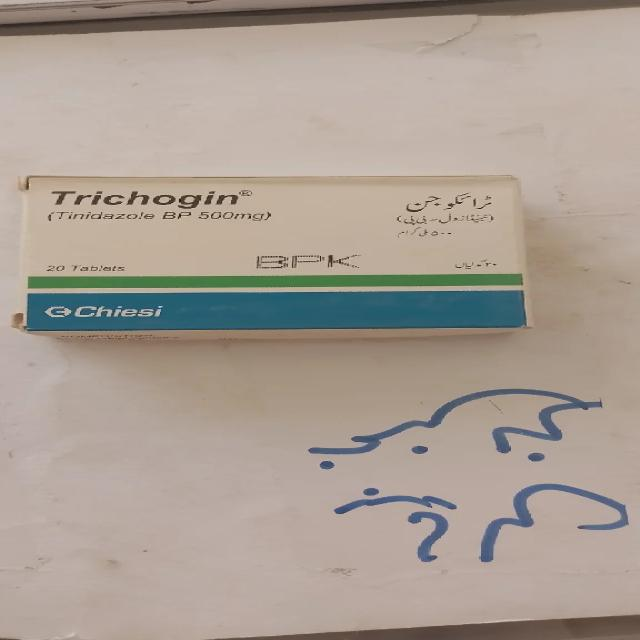


Filename: 8B5uiLOskVgkEbZPWwENbutCtAp_jpg.rf.8ca0afaad63cb64d32ad0258dc3d1d17.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


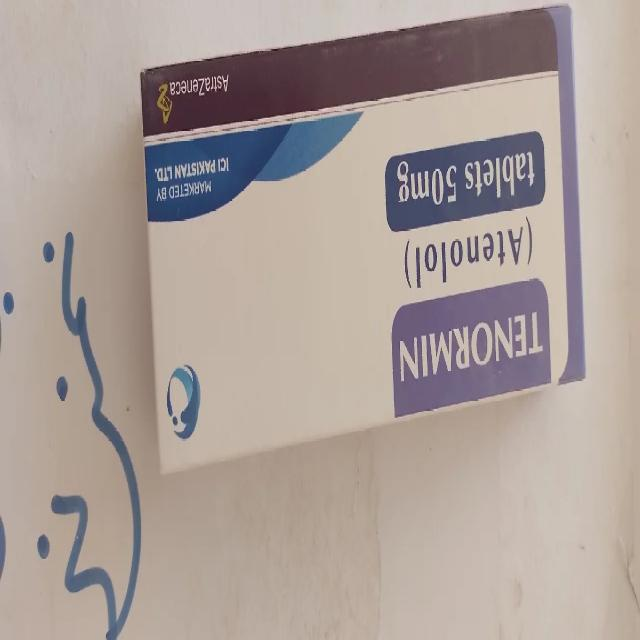


Filename: 8BDBYMUfnqQZZtOYTFRHlVPjpHo_jpg.rf.6f89cfdc1cbc485495d3b28bd7f46943.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


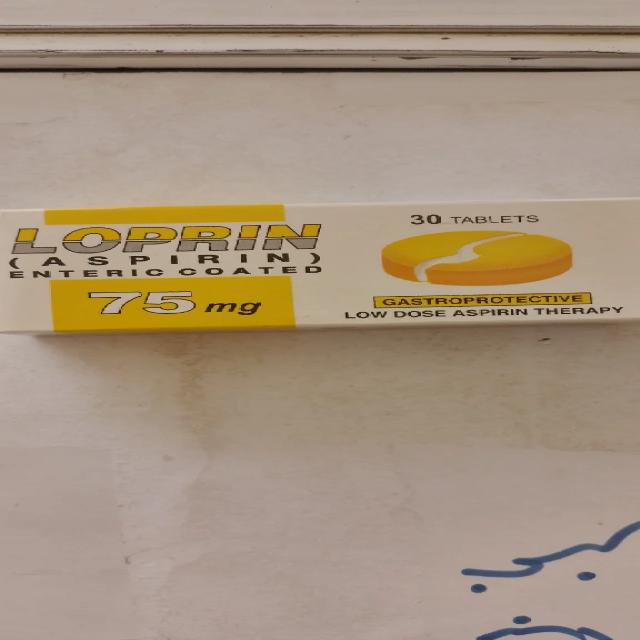


Filename: 8BEwwjzboDAWnxESPmCdVAYhRtl_jpg.rf.b59221f631214b51c2170791abbfaccc.jpg
Image size: (640, 640)
Image array shape: (640, 640, 3)


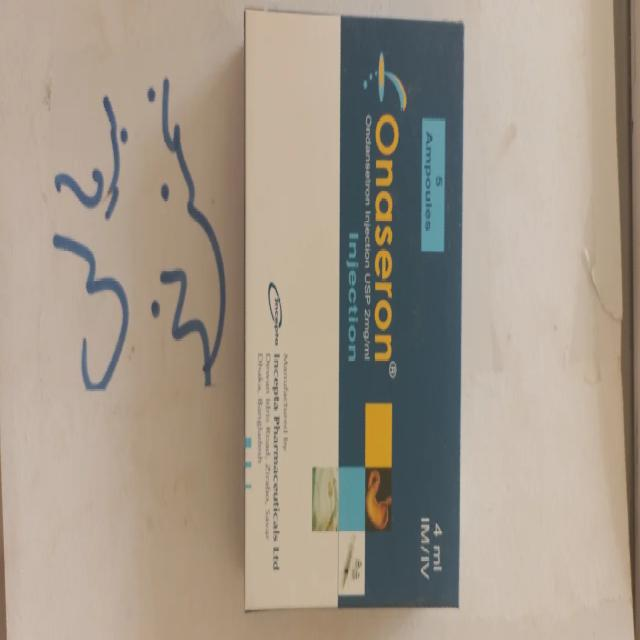


Total images processed: 15


In [7]:
images = {}

for path in file_paths:

    filename = path.split("/")[-1]

    image = Image.open(path).convert("RGB")

    image_array = np.array(image)

    images[filename] = {
        "image": image,
        "array": image_array
    }

    print("\nFilename:", filename)
    print("Image size:", image.size)
    print("Image array shape:", image_array.shape)

    display(image)

print("\nTotal images processed:", len(images))

In [8]:
all_predictions = {}

for filename, data in images.items():

    image_array = data["array"]

    predictions = predictor.predict(image_array)

    all_predictions[filename] = predictions

    print()
    print("Image:", filename)
    print("Prediction count:", len(predictions))

    for i, prediction in enumerate(predictions, start=1):
        print(f"\nPrediction {i}:")
        print(prediction)

print("\nPredictions completed for all images!")


Image: 8A-DpUCaupKUvBKXnehKynqxnPu_jpg.rf.1e4ab8c755b7bfc3fc24fbf067fec276.jpg
Prediction count: 3

Prediction 1:
score=0.43872660398483276 label_name='Tegral' label_index=11 id='15ceeb1a-b421-4fab-99a0-c7849d96592c' bboxes=(11, 224, 582, 326)

Prediction 2:
score=0.38009190559387207 label_name='Trichogin' label_index=3 id='96210954-f9c2-4439-88e5-9ab8c2e1a5e6' bboxes=(4, 225, 583, 329)

Prediction 3:
score=0.3784894645214081 label_name='Tarivid' label_index=9 id='8fb72979-46a7-4a26-9862-0e19b5745aff' bboxes=(0, 227, 581, 327)

Image: 8A2llIANwEJLkfmwibyyQGyfMXk_jpg.rf.9482eb26f019f60321947891329cff8a.jpg
Prediction count: 1

Prediction 1:
score=0.4205065369606018 label_name='Tegral' label_index=11 id='582c91eb-ab6f-4c1a-9b76-d1b96483adb2' bboxes=(14, 259, 614, 362)

Image: 8A4LMaoydMoikUOsIIlNyOLFvus_jpg.rf.23e7163f0f811f30298d09e9e95f3f6d.jpg
Prediction count: 1

Prediction 1:
score=0.5999083518981934 label_name='Yorker' label_index=13 id='0677b4c2-85f1-418b-966d-61c6f49f8a19' bboxe

In [9]:
!pip install pillow numpy gtts ipython landingai


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


Medicine Label Cognitive Assistant
Upload medicine bottle images for analysis.

Analyzing: 8A2llIANwEJLkfmwibyyQGyfMXk_jpg.rf.9482eb26f019f60321947891329cff8a.jpg


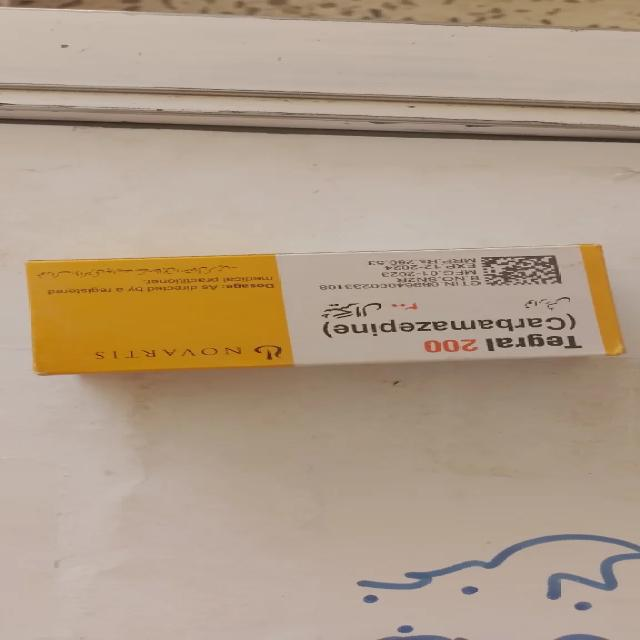


Raw model predictions:
[ObjectDetectionPrediction(score=0.4205065369606018, label_name='Tegral', label_index=11, id='778e2448-93a8-4c96-95ce-7aa7f3a8d359', bboxes=(14, 259, 614, 362))]

Detection Results:

Prediction 1:
score=0.4205065369606018 label_name='Tegral' label_index=11 id='778e2448-93a8-4c96-95ce-7aa7f3a8d359' bboxes=(14, 259, 614, 362)


### Medicine Assistant Response
**Image:** 8A2llIANwEJLkfmwibyyQGyfMXk_jpg.rf.9482eb26f019f60321947891329cff8a.jpg

**Status:** Medicine label analysis completed.


Medicine analysis completed for all uploaded images!


In [10]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io
import os

def medicine_assistant():

    print("Medicine Label Cognitive Assistant")
    print("Upload medicine bottle images for analysis.")

 

    root = Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    file_paths = filedialog.askopenfilenames(
        title="Select Medicine Images",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp")
        ]
    )

    root.destroy()

    if not file_paths:
        print("No images uploaded.")
        return

   
    for path in file_paths:

        filename = os.path.basename(path)

        print("\n" + "="*50)
        print("Analyzing:", filename)

        image = Image.open(path).convert("RGB")

        display(image)

        image_array = np.array(image)

     

        try:
            predictions = predictor.predict(image_array)

        except Exception as e:
            print("Prediction failed:", e)
            continue

        print("\nRaw model predictions:")
        print(predictions)

        if not predictions:
            print("No predictions returned by the model.")
            continue

   

        result = "Medicine label analysis completed."

        print("\nDetection Results:")

        for i, prediction in enumerate(predictions, start=1):

            print(f"\nPrediction {i}:")
            print(prediction)
   
 

        display(Markdown(
            f"### Medicine Assistant Response\n"
            f"**Image:** {filename}\n\n"
            f"**Status:** {result}"
        ))

     

        speech = gTTS(
            text=f"Medicine image analysis completed for {filename}. "
                 "Please review the displayed detection results.",
            lang="en"
        )

        audio_filename = "medicine_response.mp3"

        speech.save(audio_filename)

        display(Audio(audio_filename, autoplay=False))

    print("\nMedicine analysis completed for all uploaded images!")


medicine_assistant()

## Emotions

In [1]:

import os
from getpass import getpass
from landingai.predict import Predictor

API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "8b59b5a1-9138-4a59-8eca-df90a1de1972"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

Enter your LandingAI API Key:  ········


LandingAI predictor initialized successfully.


In [2]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_path = filedialog.askopenfilenames(
    title="Select Expression Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_path))

Total images selected: 11



Filename: 9CGt589-4aXV0laBM6Fqz-h9qL1kLioOHuEOZqN0E1KNWykW1c-j-_lX551SWhIbQ5kDKxlmyJ5dY7K7-632wrtZ2sqF3KzYSDQ7PzwBtpppwXHi3yuwmdygPj1SU6tFBTJxqJFeW2mOBsDIpFr80dRUsOzaW-iLa2sVbcWjy96H2CP-aA6e3A2-F4ArAwDR.jpeg
Image size: (500, 500)
Image array shape: (500, 500, 3)


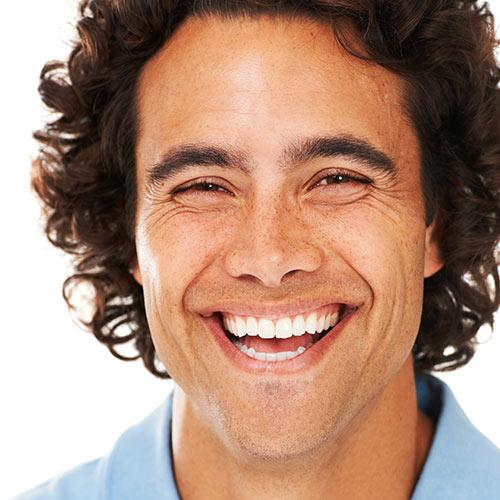


Filename: 360_F_48883681_3YSVqKeyIvDNGZ9t0A8ynIFaeo64sHDm.jpg
Image size: (461, 360)
Image array shape: (360, 461, 3)


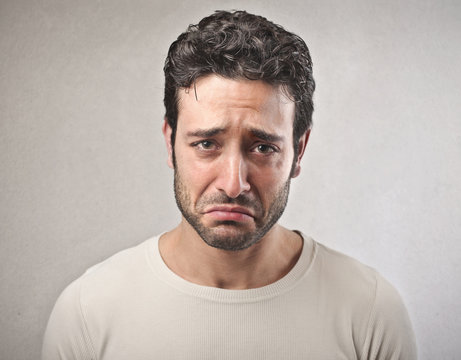


Filename: 360_F_84670412_cIAHhDJnhzvCpoZEPbLadJ3KPsaIUiRx.jpg
Image size: (459, 360)
Image array shape: (360, 459, 3)


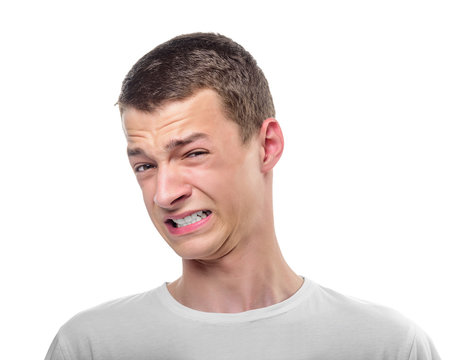


Filename: 1000_F_168542795_2942vo2O6Gfld0uvbBvbOYCljFMlw0Lo.jpg
Image size: (1000, 667)
Image array shape: (667, 1000, 3)


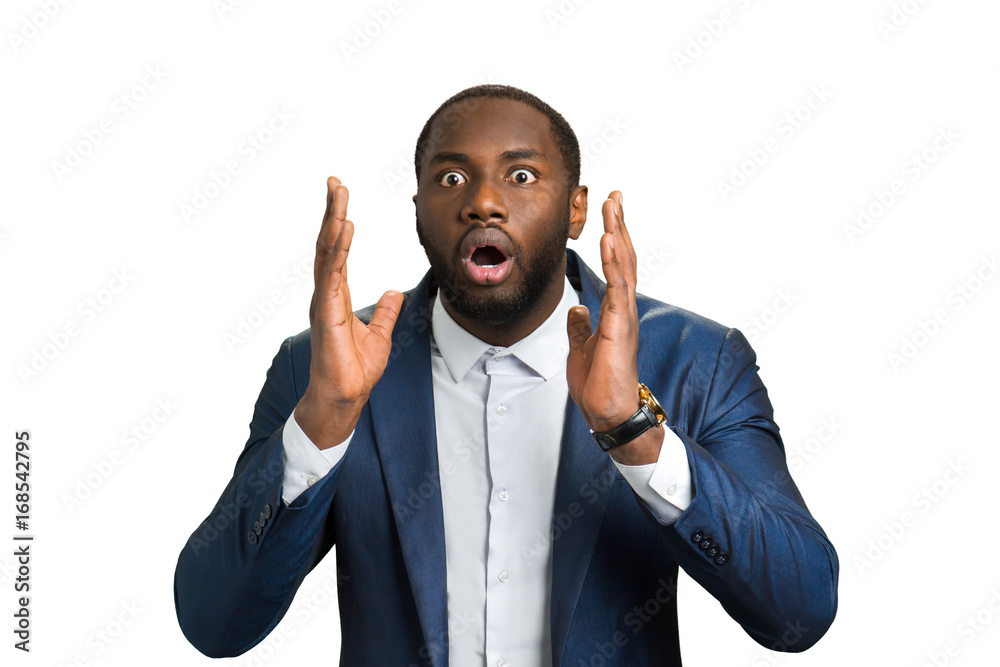


Filename: a-muscular-man-in-a-sleeveless-shirt-displays-an-intense-angry-expression-with-eyes-wide-open-and-gritted-teeth-his-face-is-prominently-focused-in-a-close-up-shot-capturing-raw-emotion-photo.jpeg
Image size: (525, 350)
Image array shape: (350, 525, 3)


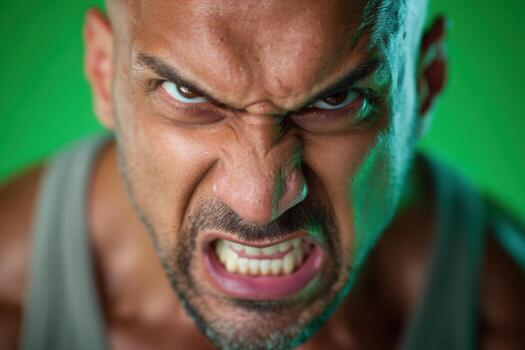


Filename: DMUbjq2UjJcG3umGv3Qjjd.jpeg
Image size: (704, 704)
Image array shape: (704, 704, 3)


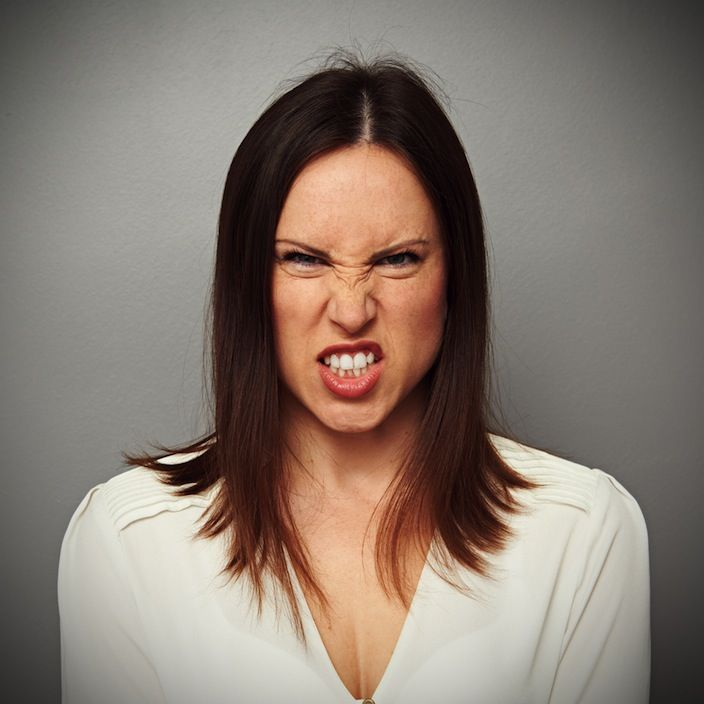


Filename: emotional-portrait-of-a-sad-woman-with-tearful-eyes-photo.jpeg
Image size: (642, 350)
Image array shape: (350, 642, 3)


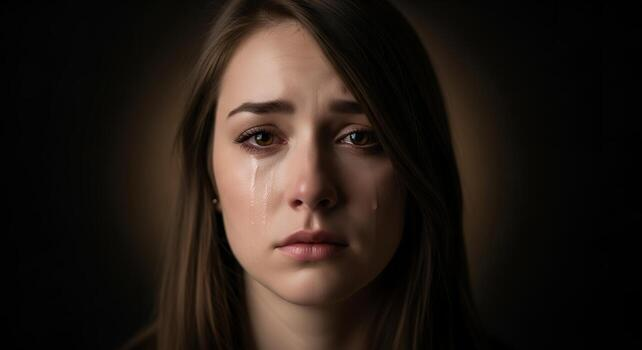


Filename: images (1).jpeg
Image size: (236, 354)
Image array shape: (354, 236, 3)


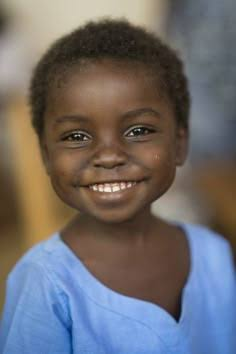


Filename: images.jpeg
Image size: (678, 452)
Image array shape: (452, 678, 3)


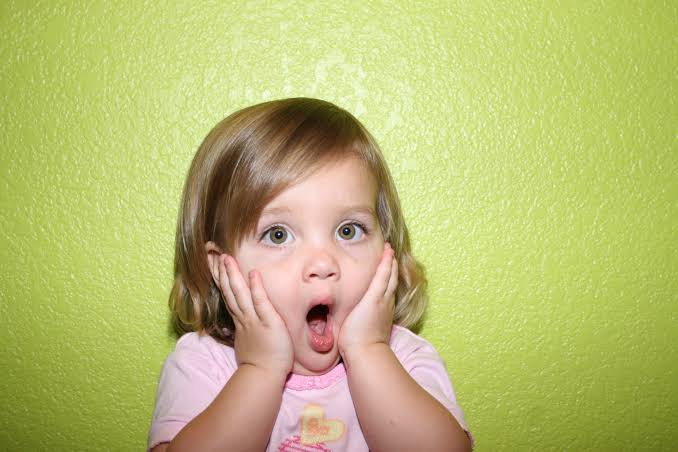


Filename: istockphoto-174868744-612x612.jpg
Image size: (612, 612)
Image array shape: (612, 612, 3)


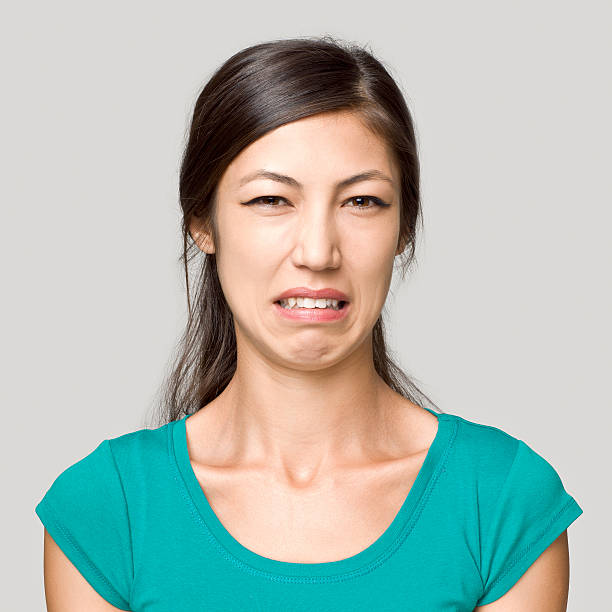


Filename: istockphoto-1042450928-612x612.jpg
Image size: (612, 395)
Image array shape: (395, 612, 3)


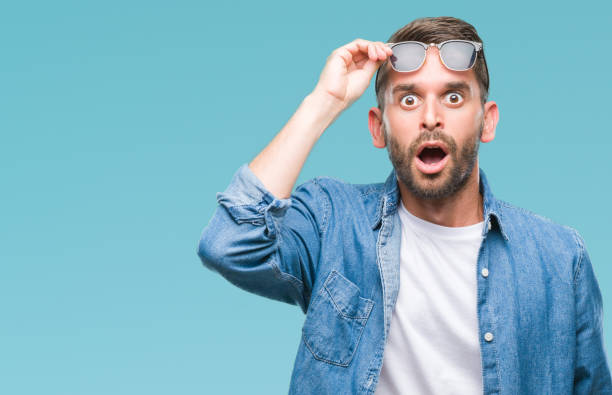


Total images processed: 11


In [3]:
images = {}

for path in file_path:

    filename = path.split("/")[-1]

    image = Image.open(path).convert("RGB")

    image_array = np.array(image)

    images[filename] = {
        "image": image,
        "array": image_array
    }

    print("\nFilename:", filename)
    print("Image size:", image.size)
    print("Image array shape:", image_array.shape)

    display(image)

print("\nTotal images processed:", len(images))

In [4]:
all_predictions = {}

for filename, data in images.items():

    image_array = data["array"]

    predictions = predictor.predict(image_array)

    all_predictions[filename] = predictions

    print()
    print("Image:", filename)
    print("Prediction count:", len(predictions))

    for i, prediction in enumerate(predictions, start=1):
        print(f"\nPrediction {i}:")
        print(prediction)

print("\nPredictions completed for all images!")


Image: 9CGt589-4aXV0laBM6Fqz-h9qL1kLioOHuEOZqN0E1KNWykW1c-j-_lX551SWhIbQ5kDKxlmyJ5dY7K7-632wrtZ2sqF3KzYSDQ7PzwBtpppwXHi3yuwmdygPj1SU6tFBTJxqJFeW2mOBsDIpFr80dRUsOzaW-iLa2sVbcWjy96H2CP-aA6e3A2-F4ArAwDR.jpeg
Prediction count: 0

Image: 360_F_48883681_3YSVqKeyIvDNGZ9t0A8ynIFaeo64sHDm.jpg
Prediction count: 3

Prediction 1:
score=0.5017926692962646 label_name='Disgust' label_index=2 id='44606827-19e2-4912-84d5-069cfa49c5ca' bboxes=(134, 9, 361, 318)

Prediction 2:
score=0.49425363540649414 label_name='Happy' label_index=1 id='67dd4fce-76b7-44b8-897a-3097257edaf2' bboxes=(134, 9, 361, 318)

Prediction 3:
score=0.44278234243392944 label_name='Sad' label_index=3 id='6f273c32-0c25-4a89-9fa1-cbc4dbb13052' bboxes=(134, 9, 361, 318)

Image: 360_F_84670412_cIAHhDJnhzvCpoZEPbLadJ3KPsaIUiRx.jpg
Prediction count: 1

Prediction 1:
score=0.4573466181755066 label_name='Disgust' label_index=2 id='3d71ab0b-1712-4646-8606-6a017057fd46' bboxes=(95, 15, 331, 360)

Image: 1000_F_168542795_2942vo2O6Gfld0uvbBvbO

In [5]:
!pip install pillow numpy gtts ipython landingai


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


Facial Expressions Cognitive Assistant
Upload facial expression images for analysis.

Analyzing: 1000_F_168542795_2942vo2O6Gfld0uvbBvbOYCljFMlw0Lo.jpg


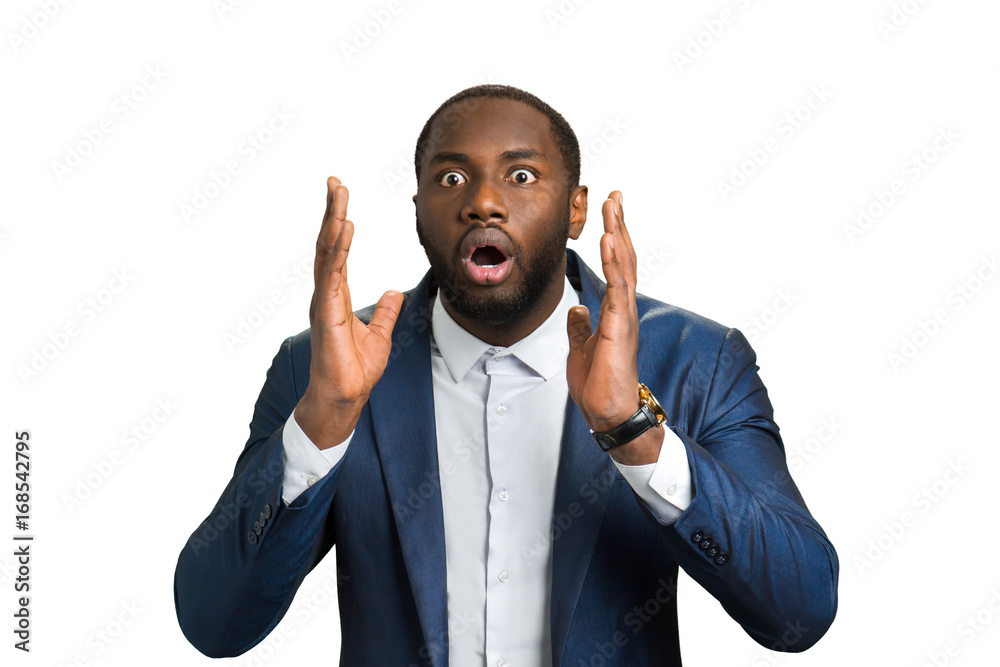


Raw model predictions:
[ObjectDetectionPrediction(score=0.6726529598236084, label_name='Surprised', label_index=4, id='9534f55d-ddb2-463a-838b-47a0d4ebf950', bboxes=(306, 58, 735, 430))]

Detection Results:

Prediction 1:
score=0.6726529598236084 label_name='Surprised' label_index=4 id='9534f55d-ddb2-463a-838b-47a0d4ebf950' bboxes=(306, 58, 735, 430)


### Facial Expressions Response
**Image:** 1000_F_168542795_2942vo2O6Gfld0uvbBvbOYCljFMlw0Lo.jpg

**Status:** Facial Expression analysis completed.


Facial Expressions analysis completed for all uploaded images!


In [6]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io
import os

def expression_assistant():

    print("Facial Expressions Cognitive Assistant")
    print("Upload facial expression images for analysis.")

 

    root = Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    file_path = filedialog.askopenfilenames(
        title="Select Expression Images",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp")
        ]
    )

    root.destroy()

    if not file_path:
        print("No images uploaded.")
        return

   
    for path in file_path:

        file = os.path.basename(path)

        print("\n" + "="*50)
        print("Analyzing:", file)

        im = Image.open(path).convert("RGB")

        display(im)

        im_array = np.array(im)

     

        try:
            prediction = predictor.predict(im_array)

        except Exception as e:
            print("Prediction failed:", e)
            continue

        print("\nRaw model predictions:")
        print(prediction)

        if not prediction:
            print("No predictions returned by the model.")
            continue

   

        result = "Facial Expression analysis completed."

        print("\nDetection Results:")

        for i, pred in enumerate(prediction, start=1):

            print(f"\nPrediction {i}:")
            print(pred)
   
 

        display(Markdown(
            f"### Facial Expressions Response\n"
            f"**Image:** {file}\n\n"
            f"**Status:** {result}"
        ))

     

        speech = gTTS(
            text=f"Facial Expressions image analysis completed for {file}. "
                 "Please review the displayed detection results.",
            lang="en"
        )

        audio_filename = "expression_response.mp3"

        speech.save(audio_filename)

        display(Audio(audio_filename, autoplay=False))

    print("\nFacial Expressions analysis completed for all uploaded images!")


expression_assistant()